# Acrobot-v1: aprender a elevar un brazo articulado con DQN

**U3 Taller 2 | Simulación de aprendizaje por refuerzo**

Este cuaderno formula el problema, audita la API real de Gymnasium, explica cada componente del DQN y analiza una ejecución reproducible. El código de entrenamiento está en [`acrobot_dqn.py`](acrobot_dqn.py): separar el experimento del relato permite probar sus invariantes sin ocultar decisiones al lector.

**Pregunta de investigación:** ¿puede un DQN que solo recibe ángulos y velocidades aprender a elevar el extremo libre antes del límite de 500 pasos? La comparación es una política aleatoria evaluada con *las mismas semillas*.

> **Regla de lectura:** una recompensa menos negativa significa que el agente llegó antes. No confundir una mejora en altura máxima con éxito: solo cuenta como éxito `terminated=True`.

## 1. Entorno y reproducibilidad

El cuaderno se diseñó para el kernel local **IMOA**, pero el experimento admite Colab. En Colab, el kernel es remoto: hay que subir/clonar estos archivos e instalar `requirements-colab.txt` sin reemplazar el PyTorch preinstalado; el código usa CUDA automáticamente si está disponible. Para este MLP pequeño, CPU es una opción válida. El notebook usa rutas relativas, no rutas de Windows.

In [1]:
from pathlib import Path
import json, platform, sys
import gymnasium as gym
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import display, Image
from acrobot_dqn import Config, QNetwork, ENV_ID, features, tip_height, run_experiment

ROOT = Path.cwd()
RESULTS = ROOT / 'results' / 'main'
print('Python:', sys.version.split()[0], '| Gymnasium:', gym.__version__, '| PyTorch:', torch.__version__)
print('Sistema:', platform.platform(), '| Dispositivo:', 'CUDA' if torch.cuda.is_available() else 'CPU')

Python: 3.12.11 | Gymnasium: 1.3.0 | PyTorch: 2.13.0+cpu
Sistema: Windows-11-10.0.26200-SP0 | Dispositivo: CPU


In [2]:
env = gym.make(ENV_ID)
obs, info = env.reset(seed=7)
print('Observacion:', env.observation_space)
print('Accion:', env.action_space)
print('Muestra:', obs, '| forma:', obs.shape, '| dtype:', obs.dtype)
print('Limite de pasos:', env.spec.max_episode_steps, '| recompensa de referencia:', env.spec.reward_threshold)
env.close()

Observacion: Box([ -1.        -1.        -1.        -1.       -12.566371 -28.274334], [ 1.        1.        1.        1.       12.566371 28.274334], (6,), float32)
Accion: Discrete(3)
Muestra: [ 0.999687    0.02501648  0.9968461   0.07935923  0.05513714 -0.05495856] | forma: (6,) | dtype: float32
Limite de pasos: 500 | recompensa de referencia: -100.0


## 2. Formulación como proceso de decisión de Markov

| Componente | En Acrobot-v1 | Consecuencia para el DQN |
|---|---|---|
| Estado observado | Vector `Box(6,)`, `float32`: `cos(θ₁)`, `sin(θ₁)`, `cos(θ₂)`, `sin(θ₂)`, `θ̇₁`, `θ̇₂` | Entrada de seis números; seno y coseno evitan el salto artificial entre `−π` y `π`. |
| Acciones | `Discrete(3)`: torque `−1`, `0`, `+1` en la segunda articulación | Tres salidas Q, una por acción. |
| Recompensa | `−1` por paso sin alcanzar la meta; `0` al alcanzar la altura objetivo | El agente debe reducir el tiempo, no acumular un premio positivo. |
| Terminación | La punta supera altura relativa `1` | Se anula el bootstrap en Bellman. |
| Truncamiento | Límite de 500 pasos | Se cierra el episodio, pero no se confunde con un estado terminal del MDP. |

El brazo empieza casi vertical hacia abajo. Debe **acumular energía mediante oscilaciones**; no basta con elegir siempre el mismo torque. La observación ya incluye velocidades, por eso no apilamos frames ni usamos una CNN. Para la red, solo normalizamos las dos velocidades por sus límites `4π` y `9π`; las cuatro coordenadas trigonométricas ya están en `[-1,1]`.

La altura diagnóstica se calcula **sin modificar la recompensa**:

`h = −cos(θ₁) − cos(θ₁ + θ₂)`.

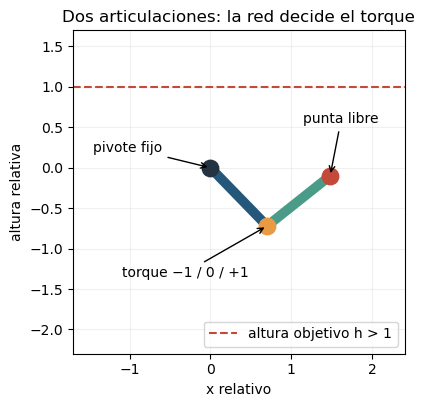

In [3]:
fig, ax = plt.subplots(figsize=(7, 4.2))
ax.set_aspect('equal'); ax.set_xlim(-1.7, 2.4); ax.set_ylim(-2.3, 1.7)
ax.axhline(1, color='#c3493a', linestyle='--', label='altura objetivo h > 1')
p0, p1, p2 = (0, 0), (0.7, -0.72), (1.48, -0.10)
ax.plot([p0[0], p1[0]], [p0[1], p1[1]], color='#24577a', lw=7, solid_capstyle='round')
ax.plot([p1[0], p2[0]], [p1[1], p2[1]], color='#4b9b89', lw=7, solid_capstyle='round')
ax.scatter(*p0, s=140, color='#243342', zorder=3)
ax.scatter(*p1, s=140, color='#e89b43', zorder=3)
ax.scatter(*p2, s=140, color='#c3493a', zorder=3)
ax.annotate('pivote fijo', p0, xytext=(-1.45, .2), arrowprops={'arrowstyle':'->'})
ax.annotate('torque −1 / 0 / +1', p1, xytext=(-1.1, -1.35), arrowprops={'arrowstyle':'->'})
ax.annotate('punta libre', p2, xytext=(1.15, .55), arrowprops={'arrowstyle':'->'})
ax.set(title='Dos articulaciones: la red decide el torque', xlabel='x relativo', ylabel='altura relativa')
ax.legend(loc='lower right'); ax.grid(alpha=.18)
plt.show()

In [4]:
print('Observacion cruda:', np.round(obs, 3))
print('Entrada normalizada:', np.round(features(obs), 3))
print('Altura inicial:', round(tip_height(obs), 3))
assert features(obs).shape == (6,)
assert features(obs).dtype == np.float32

Observacion cruda: [ 1.     0.025  0.997  0.079  0.055 -0.055]
Entrada normalizada: [ 1.     0.025  0.997  0.079  0.004 -0.002]
Altura inicial: -1.994


## 3. Red neuronal y ciclo DQN

La arquitectura es **6 → 128 ReLU → 64 ReLU → 3**. Son capas densas porque la entrada es cinemática, pequeña y estructurada; una CNN añadiría costo sin explotar ninguna estructura espacial de píxeles. La salida no es una acción ni una probabilidad: son las tres estimaciones `Q(s,a)`. La acción greedy es su `argmax`.

| Pieza | Función |
|---|---|
| ε-greedy | Explorar torques al principio; reducir ε gradualmente. |
| Replay buffer | Mezclar transiciones para reducir correlación temporal. |
| Red online | Elegir acciones y estimar `Q(s,a)`; recibe gradientes. |
| Red target | Calcular el objetivo con parámetros congelados entre sincronizaciones. |
| Huber + clipping | Reducir sensibilidad a errores TD grandes. |

**Flujo:** observación → normalización → elección ε-greedy → transición → replay → minibatch → objetivo de Bellman → pérdida → actualización online → sincronización periódica de target.

In [5]:
model = QNetwork()
print(model)
print('Parametros entrenables:', sum(p.numel() for p in model.parameters()))
with torch.no_grad():
    print('Tres Q-valores iniciales:', model(torch.as_tensor(features(obs))).numpy().round(3))

QNetwork(
  (layers): Sequential(
    (0): Linear(in_features=6, out_features=128, bias=True)
    (1): ReLU()
    (2): Linear(in_features=128, out_features=64, bias=True)
    (3): ReLU()
    (4): Linear(in_features=64, out_features=3, bias=True)
  )
)
Parametros entrenables: 9347
Tres Q-valores iniciales: [ 0.073 -0.028  0.134]


### La actualización central

`y = r + γ(1 − terminated) maxₐ Q_target(s',a)`<br>
`L = Huber(Q_online(s,a), y)`

Si `terminated=True`, no hay futuro y `y=r`. Si se agotaron los 500 pasos (`truncated=True`), registramos el fin del episodio pero mantenemos el bootstrap: el límite de tiempo es externo a la dinámica del brazo. Esta distinción evita un error frecuente al migrar de `done` a la API actual de Gymnasium.

In [6]:
gamma, reward, next_q = 0.99, -1.0, -25.0
print('Objetivo no terminal:', reward + gamma * next_q)
print('Objetivo terminal:', reward)

Objetivo no terminal: -25.75
Objetivo terminal: -1.0


## 4. Protocolo experimental

Se entrena con semillas independientes `11, 29, 47`. Cada 50 episodios se mide desempeño greedy con 20 semillas de **validación** (para elegir checkpoint). El resultado final usa 50 semillas **de prueba separadas**, idénticas para DQN y política aleatoria. Así evitamos llamar “resultado” a una curva exploratoria de entrenamiento. El checkpoint guardado es el de mejor media de validación; el archivo `final.pt` conserva también la última red.

Hiperparámetros principales: `γ=0.99`, Adam `lr=0.001`, lote `64`, memoria `100 000`, aprendizaje cada `4` pasos después de `1 000` transiciones, red target cada `2 000` pasos, ε lineal de `1.0` a `0.05` en `80 000` pasos, pérdida Huber, norma máxima de gradiente `10`. El horizonte de entrenamiento es `600` episodios por semilla.

La recompensa para entrenar y evaluar es exactamente la del entorno; altura máxima es **solo un diagnóstico**. El límite de referencia oficial es recompensa media `−100`, no una garantía de logro.

In [7]:
# El modo por defecto analiza la ejecución ya guardada. Cambiar a True para reentrenar.
REENTRENAR = False
if REENTRENAR:
    run_experiment(Config(episodes=600), [11, 29, 47], RESULTS)
assert (RESULTS / 'summary.json').exists(), 'Ejecuta primero acrobot_dqn.py o activa REENTRENAR.'
summary = json.loads((RESULTS / 'summary.json').read_text(encoding='utf-8'))
display(pd.DataFrame(summary['dqn_by_seed']))
display(pd.DataFrame([{'agente':'Aleatorio', **summary['random_baseline']}]))

,seed,mean_reward,std_reward,median_reward,success_rate,mean_steps,mean_maximum_height
0,11,-94.88,22.947713,-88.0,1.00,95.88,1.208154
1,29,-500.00,0.000000,-500.0,0.00,500.00,-1.226353
2,47,-366.16,114.605510,-321.0,0.62,366.78,0.006406


,agente,mean_reward,std_reward,median_reward,success_rate,mean_steps,mean_maximum_height
0,Aleatorio,-500.0,0.0,-500.0,0.0,500.0,-0.397156


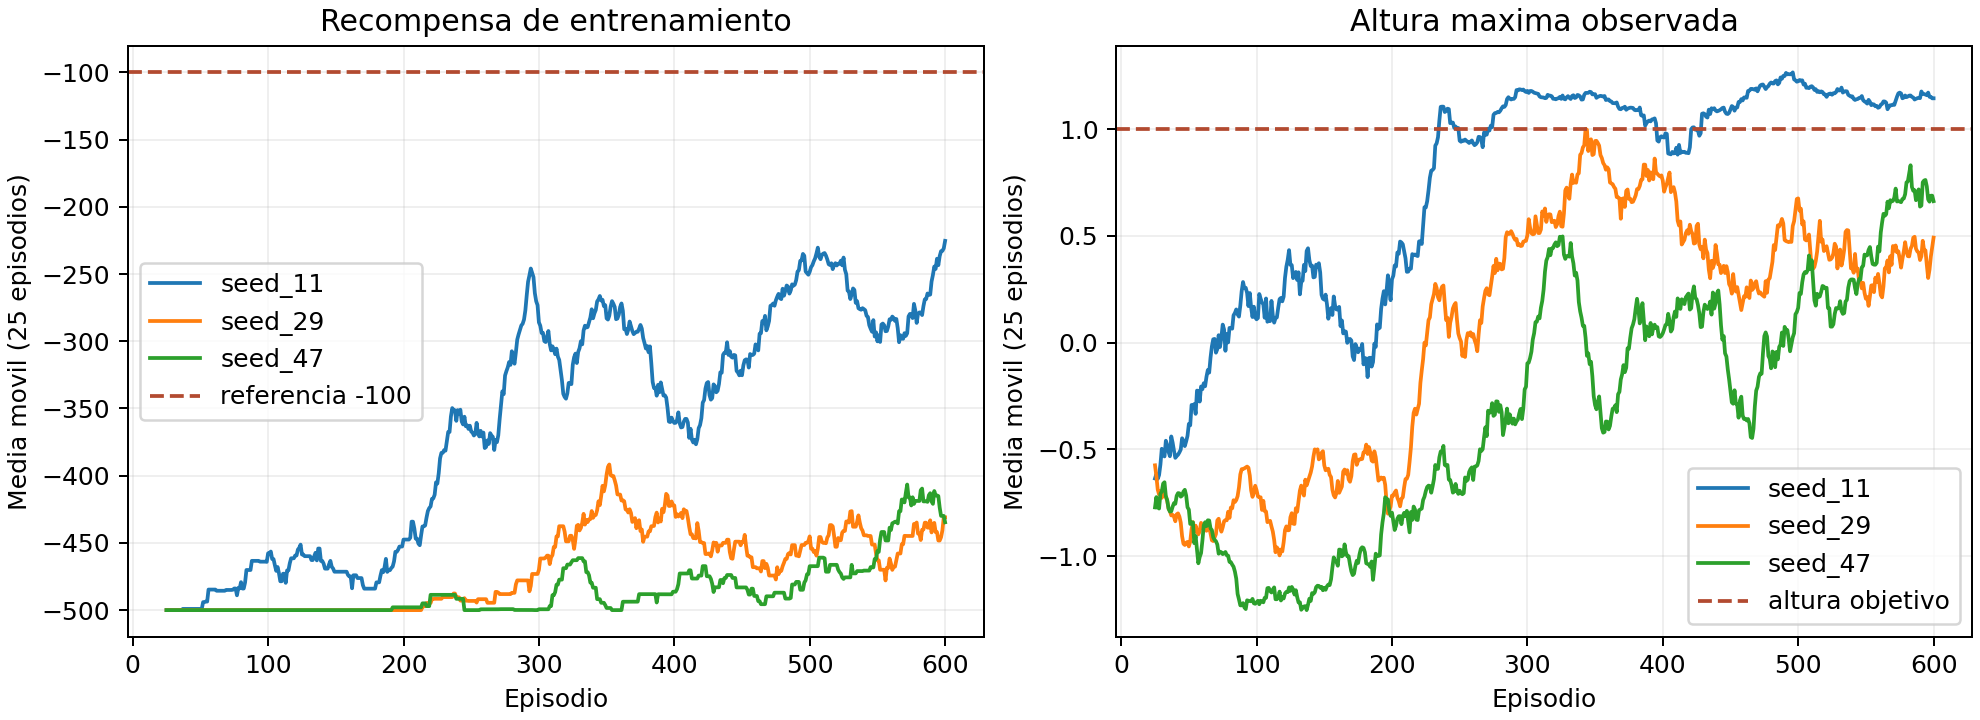

In [8]:
display(Image(filename=str(RESULTS / 'learning_curve.png')))

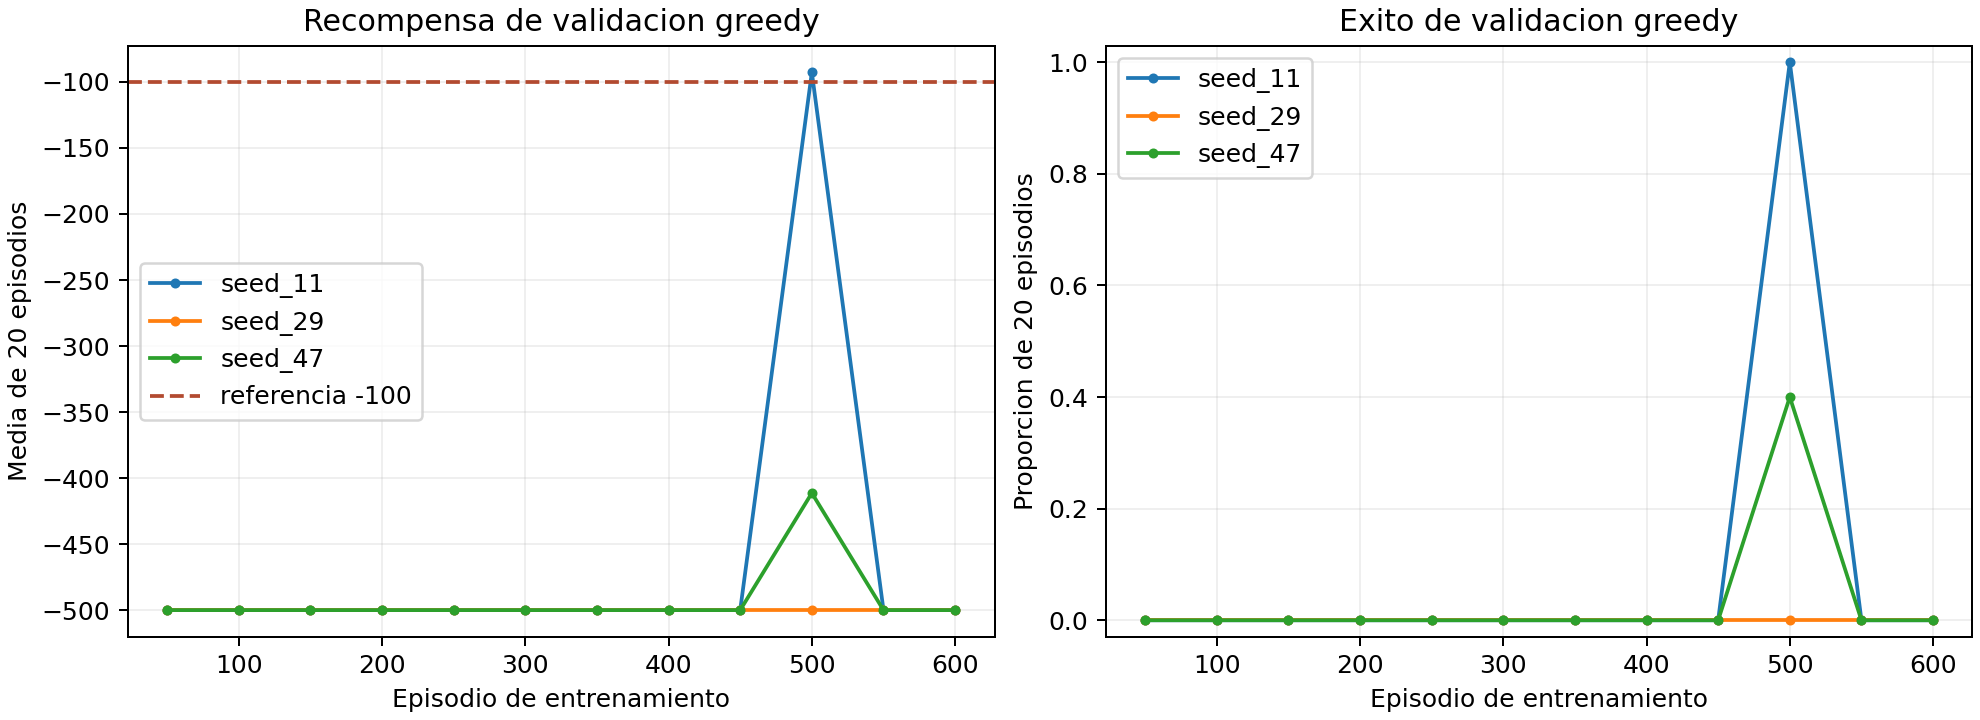

In [9]:
display(Image(filename=str(RESULTS / 'validation_curve.png')))

## 5. Lectura crítica

En las 50 condiciones de prueba, el DQN con semilla **11** resolvió `50/50` episodios con recompensa media `−94.88`; es el único que superó la referencia `−100`. La semilla **47** resolvió `31/50` y obtuvo `−366.16`. La **29** no resolvió ninguno (`−500`), igual que el baseline aleatorio. La tasa conjunta `81/150 = 54 %` no debe esconder esta gran variación.

La gráfica de validación revela algo que la curva de entrenamiento oculta: las políticas de las semillas 11 y 47 fueron útiles en el episodio 500, pero en el 600 **las tres redes finales** cayeron a `−500`. El checkpoint se eligió usando solo validación y se midió después en semillas de prueba independientes. Es una protección contra el colapso, no evidencia de aprendizaje estable.

La semilla 29 llegó a la meta en 159 episodios **durante exploración**, sin aprender una política greedy exitosa. La altura máxima ayuda a entender la diferencia entre agitar el brazo y coordinar una oscilación que cruce `h > 1`. El obstáculo estructural es la recompensa casi siempre `−1`: la señal útil llega tarde y el bootstrap puede amplificar estimaciones inestables. Tres semillas dan evidencia de sensibilidad, no una garantía de generalización.

**Fuentes:** [Gymnasium Acrobot-v1](https://gymnasium.farama.org/environments/classic_control/acrobot/), [API `terminated`/`truncated`](https://gymnasium.farama.org/api/env/), [Mnih et al., DQN](https://arxiv.org/abs/1312.5602). Las figuras y el código de este taller son propios.